In [ ]:
BRANCH = "main"

%cd /tmp
!rm -rf damage-detection
!git clone -b {BRANCH} https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .

/tmp
Cloning into 'damage-detection'...
remote: Enumerating objects: 228, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 228 (delta 11), reused 24 (delta 5), pack-reused 161 (from 1)
Receiving objects: 100% (228/228), 11.37 MiB | 31.64 MiB/s, done.
Resolving deltas: 100% (90/90), done.
/tmp/damage-detection
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done


In [2]:
import segmentation_models_pytorch as smp

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import cv2
from pathlib import Path
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader, Subset

from src.models.baseline_unet import BaselineUNet
from src.data.dataset import XBDDataset
from src.metrics.xview2 import XView2Metric
from src.losses.combined_loss import CombinedLoss
from src.losses.weights import compute_class_weights
from src.data.masks import get_mask_path
from src.train import fit
from src.utils.config import load_config

In [4]:
ROOT = Path("/kaggle/input/datasets/qianlanzz/xbd-dataset/xbd")
MASK_ROOT = Path("/kaggle/input/notebooks/azra41221/03-preprocessing-split/masks")

## 1. Dataset
Testing `dataset.py` files.
- Has normalization been applied? Is the data to be fed into the model in tensor format?

### test the tensor format

In [5]:
train_ds = XBDDataset("splits/train.csv", ROOT, MASK_ROOT, train=True)
val_ds = XBDDataset("splits/val.csv", ROOT, MASK_ROOT, train=False)
print("Train:", len(train_ds), " Val:", len(val_ds))

pre, post, mask = train_ds[0]
print("Train sample:", pre.shape, post.shape, mask.shape, mask.dtype, mask.unique())

pre, post, mask = val_ds[0]
print("Val sample:  ", pre.shape, post.shape, mask.shape, mask.dtype, mask.unique())

Train: 6620  Val: 2207
Train sample: torch.Size([3, 512, 512]) torch.Size([3, 512, 512]) torch.Size([512, 512]) torch.int64 tensor([0, 1])
Val sample:   torch.Size([3, 1024, 1024]) torch.Size([3, 1024, 1024]) torch.Size([1024, 1024]) torch.int64 tensor([  0, 255])


### test after augmentation
Do the pre, post, and mask still overlap after augmentation?

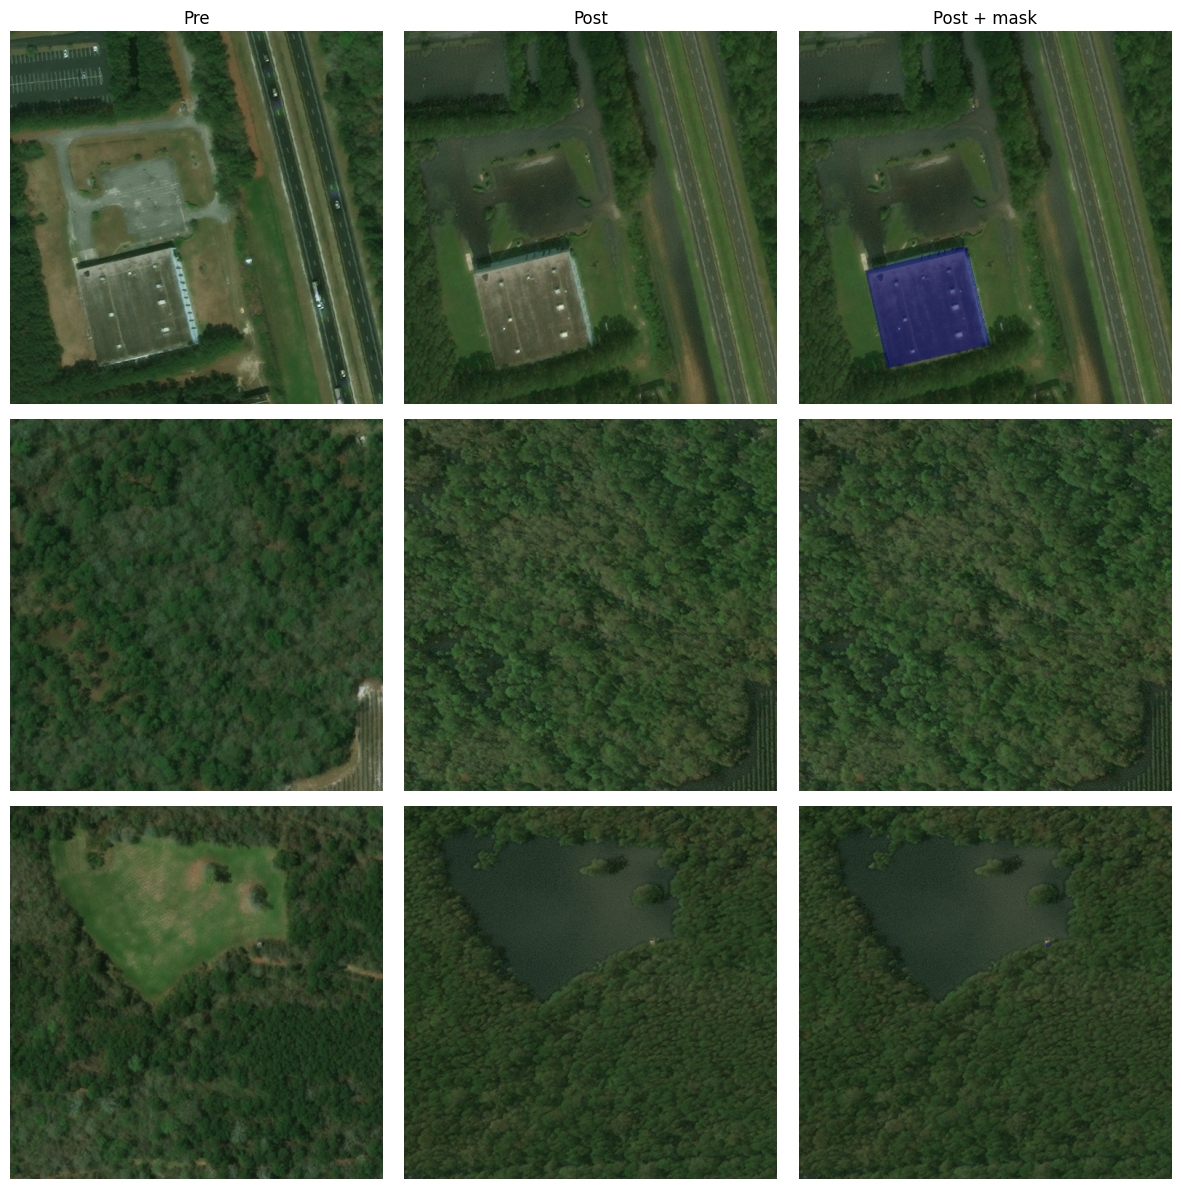

In [6]:
# ImageNet mean and standard deviation 
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def to_image(tensor):
    image = tensor.numpy().transpose(1, 2, 0)
    image = image * STD + MEAN
    return np.clip(image, 0, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row in range(3):
    pre, post, mask = train_ds[row + 100]
    axes[row, 0].imshow(to_image(pre))
    axes[row, 1].imshow(to_image(post))
    axes[row, 2].imshow(to_image(post))
    axes[row, 2].imshow(np.ma.masked_where(mask.numpy() == 0, mask.numpy()), alpha=0.5, cmap="jet")

axes[0, 0].set_title("Pre")
axes[0, 1].set_title("Post")
axes[0, 2].set_title("Post + mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Dataset check**
- Train samples are random 512×512 crops; val samples are full 1024×1024 images.
- Pre, post and mask stay aligned after random crops, flips and rotations.
- Many crops contain no buildings (2 of the 3 samples shown) → empty crops should be undersampled during training.

## 2. Metric

In [7]:
target = torch.tensor([0, 0, 1, 2, 3, 255])
pred = torch.tensor([0, 2, 1, 3, 0, 1])

metric = XView2Metric()
metric.update(pred, target)

print("Localization [TP, FP, FN]:", metric.loc)
print("Damage [TP, FP, FN]:", metric.dmg)
print(metric.compute_f1())

Localization [TP, FP, FN]: [2, 1, 1]
Damage [TP, FP, FN]: {1: [1, 0, 0], 2: [0, 0, 1], 3: [0, 1, 1], 4: [0, 0, 0]}
{'score': 0.19999999999999998, 'f1_loc': 0.6666666666666666, 'f1_dmg': 0.0, 'f1_per_class': {1: 1.0, 2: 0.0, 3: 0.0, 4: 0.0}}


## 3. Losses

In [8]:
# test
loss_fn = CombinedLoss()

target = torch.randint(0, 5, (2, 64, 64))
target[:, :8, :8] = 255

# random predictions
random_logits = torch.randn(2, 5, 64, 64)
print("Random prediction: ", loss_fn(random_logits, target).item())

# perfect predictions
perfect_logits = torch.zeros(2, 5, 64, 64)
safe_target = target.clone()
safe_target[target == 255] = 0
perfect_logits.scatter_(1, safe_target.unsqueeze(1), 20.0)
print("Perfect prediction:", loss_fn(perfect_logits, target).item())

Random prediction:  1.1644266843795776
Perfect prediction: 0.0


**Loss check** 
The combined loss is high for random predictions (1.16) and zero for perfect predictions, and it handles ignored pixels (255) without producing NaN.

## 4. Class weights

In [9]:
counts = np.zeros(256) 

for folder, image_id in zip(train_ds.pairs["folder"], train_ds.pairs["image_id"]):
    mask = cv2.imread(str(get_mask_path(MASK_ROOT, folder, image_id)), cv2.IMREAD_GRAYSCALE)
    counts += np.bincount(mask.ravel(), minlength=256)

pixel_counts = counts[:5]

print("Pixels per class:", pixel_counts)
print("Frequency (%):", (pixel_counts / pixel_counts.sum() * 100).round(2))

Pixels per class: [6.69210298e+09 1.85321024e+08 2.22716010e+07 2.39023520e+07
 1.42937010e+07]
Frequency (%): [96.46  2.67  0.32  0.34  0.21]


In [10]:
weights = compute_class_weights(pixel_counts)
print("Class weights:", weights)

Class weights: tensor([0.0797, 0.4791, 1.3820, 1.3340, 1.7251])


**Class weights** 
Computed from the training masks with smoothed inverse frequency (1/√f): 
- background 0.080, no-damage 0.479, minor 1.382, major 1.334, destroyed 1.725. Destroyed pixels get ~22× the weight of background pixels (instead of ~500× with plain inverse frequency).

[0.0797, 0.4791, 1.3820, 1.3340, 1.7251]

## 5. Model
U-Net model

In [11]:
model = BaselineUNet()

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params / 1e6:.1f} million")

pre, post, mask = train_ds[100]
logits = model(pre.unsqueeze(0), post.unsqueeze(0))
print("Input:", post.shape, " Output:", logits.shape)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 24.4 million
Input: torch.Size([3, 512, 512])  Output: torch.Size([1, 5, 512, 512])


## 6. Training Loop

In [12]:
train_data_loader = DataLoader(
    train_ds,
    batch_size = 8,
    shuffle = True,
    num_workers = 2
)

val_data_loader = DataLoader(
    val_ds,
    batch_size = 2,
    shuffle = False,
    num_workers = 2
)

pre, post, mask = next(iter(train_data_loader)) # first batch
print("First train batch:", pre.shape, post.shape, mask.shape)

First train batch: torch.Size([8, 3, 512, 512]) torch.Size([8, 3, 512, 512]) torch.Size([8, 512, 512])


- before DataLoader [1, 512, 512]
- after DataLoader [8, 512, 512]

### test all before training

In [13]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [14]:
sample_train = Subset(train_ds, range(64))
sample_val = Subset(val_ds, range(16))

train_data_loader = DataLoader(sample_train, batch_size=8, shuffle=True, num_workers=2)
val_data_loader = DataLoader(sample_val, batch_size=2, shuffle=False, num_workers=2)

weights = torch.tensor([0.0797, 0.4791, 1.3820, 1.3340, 1.7251])

model = BaselineUNet().to(device)
loss_fn = CombinedLoss(alpha=weights, gamma=2.0, lam=0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

best = fit(model, train_data_loader, val_data_loader, loss_fn, optimizer, device,
           max_epochs=3, out_dir="/kaggle/working/test_run")
print("Best val score:", best)

epoch 1/3  train loss 0.5459  val score 0.0483 (loc 0.0379, dmg 0.0527)
  -> new best model saved
epoch 2/3  train loss 0.5359  val score 0.0508 (loc 0.0399, dmg 0.0555)
  -> new best model saved
epoch 3/3  train loss 0.5260  val score 0.0503 (loc 0.0439, dmg 0.0531)
Early stopping: no improvement for 1 epochs
Best val score: 0.050815269856719775


**First training run** 
64 train / 16 val samples, 3 epochs on GPU. The training loss decreases and the validation score increases at every epoch; `best.pt`, `last.pt` and `log.csv` are created. Scores are very low as expected for such a small run; the goal was only to check that the whole pipeline runs end to end.

## 7. Santity Check

In [15]:
config = load_config("configs/baseline.yaml")

# first batch 
pre, post, mask = next(iter(train_data_loader))
pre = pre.to(device)
post = post.to(device)
mask = mask.to(device)

model = BaselineUNet().to(device)

loss_fn = CombinedLoss(alpha=torch.tensor(config["loss"]["class_weights"]),
                       gamma=config["loss"]["gamma"], lam=config["loss"]["lam"])
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

# show the same batch 200 times
model.train()
for step in range(1, 201):
    logits = model(pre, post)
    loss = loss_fn(logits, mask)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if step % 20 == 0:
        print(f"step {step}  loss {loss.item():.4f}")

# score on the same batch
model.eval()
with torch.no_grad():
    pred = model(pre, post).argmax(dim=1)
metric = XView2Metric()
metric.update(pred, mask)
print(metric.compute_f1())

step 20  loss 0.4237
step 40  loss 0.3910
step 60  loss 0.3811
step 80  loss 0.3388
step 100  loss 0.3979
step 120  loss 0.2711
step 140  loss 0.2601
step 160  loss 0.2571
step 180  loss 0.2550
step 200  loss 0.2221
{'score': 0.29039957629612195, 'f1_loc': 0.9679985876537398, 'f1_dmg': 0.0, 'f1_per_class': {1: 0.9815651393136732, 2: 0.0, 3: 0.973568281938326, 4: 0.0}}


**Sanity check** 
The model was trained 200 steps on a single fixed batch.The loss keeps decreasing; it does not reach zero.